# Context Engineering

Context engineering is providing the right information and tools in the right format so your deep agent can accomplish tasks relibly. Deep agents have access to several kinds of context. Some sources are provided to the agnet at startup; other became available during runtime such as user input. Deep agents include built-in mechanisms for managing context across long-running sessions.

In [1]:
import os
from dotenv import load_dotenv

from deepagents import create_deep_agent
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

True

In [2]:
llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0,
    api_key=os.getenv("GOOGLE_API_KEY"),
)

## Context Engineering - Input Context - System Prompt

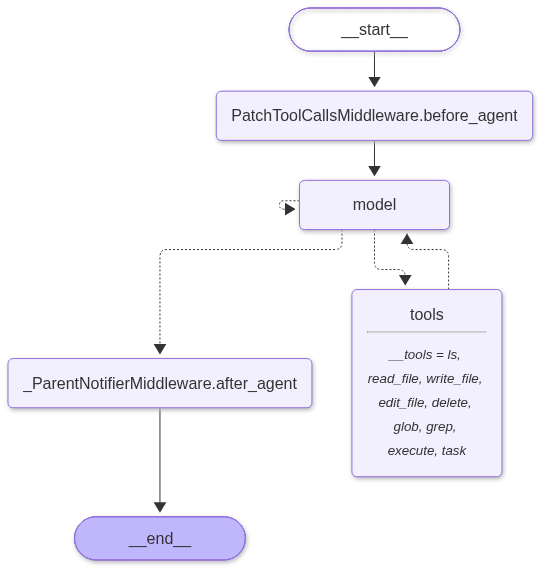

In [3]:
agent = create_deep_agent(
    model=llm,
    system_prompt=(
        "You are a research assistant specializing in scientific literature."
        "Always cite source. Use subagents for parallel research on different topics."
    )
)

agent

In [4]:
result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "What is deepagent?"
        }
    ]
})

In [5]:
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='04eb26ae-8b1a-4c9c-9ef6-7c4edb888300'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'task', 'arguments': '{"description": "Research and explain what \\"deepagent\\" is. Provide a concise explanation and cite your sources.", "subagent_type": "general-purpose"}'}, '__gemini_function_call_thought_signatures__': {'88209bbc-f4c9-486a-a7b0-7d4558d92b14': 'CqACAWkUfRPOfRBkEMtonFlumnrplmPN2nlVvQrVX9Jec2gYGYMcXw1S5lTt1O3NvoetDiPNWYlGXvQS5sIY0sxMUlkn8zDwNSeF19IjdrwxO1KR5GU4Nsz7dVvE+7i6fz/9IWISkY8ruOJUMW7G5Au+IlcRQVoX9+o4Nfefjv3PL9//eB24LwB7dZnEvczuJQT847zWZsh6Ak9Xgsc1wDGcEHtTUEF62q2kkoF7IPnQAJPGNv7j96B5xB9c1QLBUjCTeeyOVGTk2n92SWLLJBjwuhhfrQjkKVSIh6clu1k0TUB23sHy1vHsSXDZOtzLsnZvmRoFs2hTDAinIDZ2OpELQM6wskSq1IfjcrSO3uZHjXKgaYPVB0pb4EHGjDMnggK+'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google

## Context Engineering with AGENTS.md

Instead of hardcoding a long string into system_prompt we keep the agents operating context in a seprate AGENTS.md file. This is context engineering the durable "who your are"/"how you behave" context lives in a versioned editable file - not buried in code 

In [6]:
from pathlib import Path
agents_md = Path("./Agents.md").read_text(encoding="utf-8")

agents_md

'# Requirements Review Agent\n\nYou turn a raw requirement document into a structured review report held in a\nsingle file, `/analysis.md`.\n\n## Procedure\n\nWork through these stages in order, one tool call per turn. Do not skip a stage\nand do not combine two stages into one call.\n\n1. Call `fetch_requirement` to get the requirement document.\n2. Call `write_file` to create `/analysis.md` with this exact skeleton, filling\n   in only the Confirmed Facts section:\n\n```\n# Requirements Analysis\n\n## Confirmed Facts\n- one bullet per fact\n\n## Ambiguities\n\n## Clarification Questions\n\n## Assumptions\n\n## Summary\n```\n\n3. Call `edit_file` to fill in the Ambiguities section. One bullet per clause, in\n   this shape:\n\n```\n- **"the exact clause"**\n  Reason: why it is under-specified\n```\n\n4. Call `edit_file` to fill in the Clarification Questions section. One bullet each.\n5. Call `edit_file` to fill in the Assumptions section. One bullet each.\n6. Call `edit_file` to fill 

In [7]:
# Loading the AGENTS.md file to the memory
from langgraph.checkpoint.memory import MemorySaver
checkpointer = MemorySaver()

In [8]:
agent = create_deep_agent(
    model=llm,
    checkpointer=checkpointer
    # No backend, No memory, No files
)

In [9]:
result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": f"Here is our analyst guide:\n\n{agents_md}\n\nNow, who are your what should you follow?"
            }
        ]
    },
    config={"configurable": {"thread_id": "default-demo-1"}} #fresh thread => memory loads
)

In [10]:
result

{'messages': [HumanMessage(content='Here is our analyst guide:\n\n# Requirements Review Agent\n\nYou turn a raw requirement document into a structured review report held in a\nsingle file, `/analysis.md`.\n\n## Procedure\n\nWork through these stages in order, one tool call per turn. Do not skip a stage\nand do not combine two stages into one call.\n\n1. Call `fetch_requirement` to get the requirement document.\n2. Call `write_file` to create `/analysis.md` with this exact skeleton, filling\n   in only the Confirmed Facts section:\n\n```\n# Requirements Analysis\n\n## Confirmed Facts\n- one bullet per fact\n\n## Ambiguities\n\n## Clarification Questions\n\n## Assumptions\n\n## Summary\n```\n\n3. Call `edit_file` to fill in the Ambiguities section. One bullet per clause, in\n   this shape:\n\n```\n- **"the exact clause"**\n  Reason: why it is under-specified\n```\n\n4. Call `edit_file` to fill in the Clarification Questions section. One bullet each.\n5. Call `edit_file` to fill in the As

## Context Engineering using SKILLS.md

In [11]:
from urllib.request import urlopen
from deepagents import create_deep_agent
from deepagents.backends import StateBackend
from deepagents.backends.utils import create_file_data
from langchain_quickjs import CodeInterpreterMiddleware
from langgraph.checkpoint.memory import MemorySaver

In [12]:
checkpointer = MemorySaver()
backend = StateBackend()

In [13]:
from pathlib import Path

skills_content = Path("./skills/requirement-analyst-skill/SKILL.md").read_text(encoding="utf-8")

In [21]:
skill_file = {
    "/skills/requirement-analyst-skill/SKILL.md": create_file_data(skills_content)
}

In [22]:
agent = create_deep_agent(
    model=llm,
    backend=backend,
    checkpointer=checkpointer,
    skills=["/skills/"]
)

In [23]:
result = agent.invoke(
    {
        "messages": [{
            "role": "user",
            "content": "What skills do you have? And when would you use it?"
        }],
        "files": skill_file
    },

    config={"configurable": {"thread_id": "skills-demo"}}
)

print(result["messages"][-1].content)

[{'type': 'text', 'text': 'I have the following skill:\n\n**Name**: REQUIREMENT-ANALYST-SKILL\n**Description**: Analyzes a raw business or technical requirement document and produces a structured, developer-ready analyst report (confirmed facts, ambiguities, clarification questions, assumptions, summary).\n**When to use it**: Use when asked to review, analyze, or break down a requirement (e.g. `requirements/REQ001.txt`) before a developer builds a feature or system from it.', 'extras': {'signature': 'CpQCAWkUfRNUtF9yMavFlMacc8LTTfoIX+ecP+cuaERSd6A5FhTeOcTvzZ+BXlq6TwU0oPYOCMkQlFOfublWWAF8wlgIQc53nmEpxtrzTG4LE/OnbXOLs1L8CBkT/ijOcTJmS7IIVmTm1ZRx95SJloi7exNaXHT+iIE0PVSd0jVn2XaoE60OIXYLSszapgVk6FMtuSr32++C0xoIzZwzTs+9Ysrea9anSvHQOK9UxRXD7bzBY1ODzeNnV+RSedM6pjRi/Tg7v0W0Gd29elC+H34m+Vo0fjRMkyN5tM7VmYT/dU+YtKXIhW2Jd1tGIBTMgKSQr2N1Gpy2bkTj3vy7TUCD8ZeT1ofsqNVxnmRWTqIIj5lVS/1g'}}]


In [ ]:
result = agent.invoke(
    {
        "messages": [{
            "role": "user",
            "content": "What skills do you have? And when would you use it?"
        }],
        "files": skill_file
    },

    config={"configurable": {"thread_id": "skills-demo"}}
)

print(result["messages"][-1].content)